In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Environment size
X_MAX = 100
Y_MAX = 100

# Number of UAVs
N_UAVS = 2

# Fixed number of waypoints for each UAV
N_WAYPOINTS = 4

# Minimum allowed distance between UAVs
D_MIN = 10

In [5]:
starts = np.array([
    [0, 0],       # UAV 1 start
    [0, 100]      # UAV 2 start
])

targets = np.array([
    [100, 100],   # UAV 1 target
    [100, 0]      # UAV 2 target
])

In [7]:
# Obstacles 
# Format: [x_min, x_max, y_min, y_max]

obstacles = [
    [45, 55, 45, 55],   # Obstacle 1
    [45, 55, 75, 82]    # Obstacle 2
]

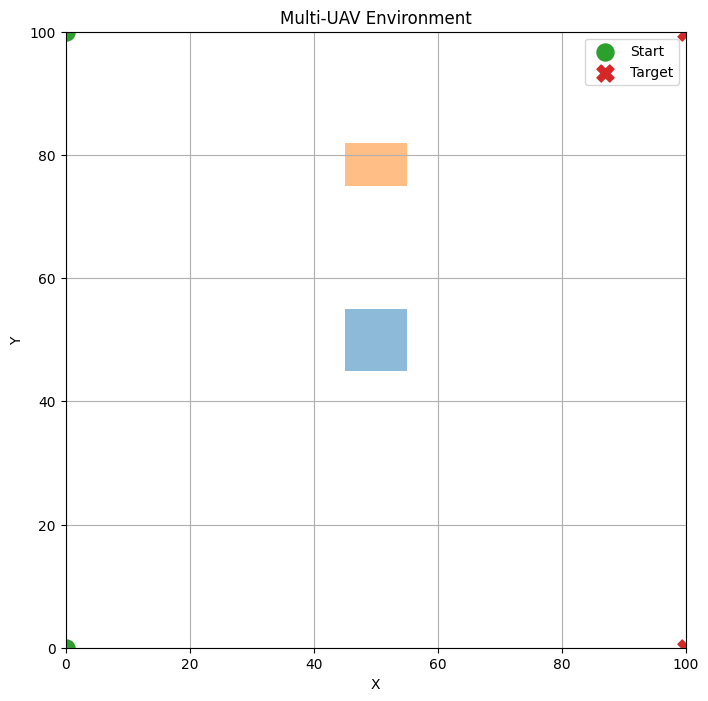

In [8]:
def plot_environment():

    plt.figure(figsize=(8, 8))

    # Plot obstacles
    for obstacle in obstacles:

        x_min, x_max, y_min, y_max = obstacle

        plt.fill(
            [x_min, x_max, x_max, x_min],
            [y_min, y_min, y_max, y_max],
            alpha=0.5
        )

    # Plot starting positions
    plt.scatter(
        starts[:, 0],
        starts[:, 1],
        marker='o',
        s=150,
        label='Start'
    )

    # Plot target positions
    plt.scatter(
        targets[:, 0],
        targets[:, 1],
        marker='X',
        s=150,
        label='Target'
    )

    plt.xlim(0, X_MAX)
    plt.ylim(0, Y_MAX)

    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title("Multi-UAV Environment")

    plt.grid()
    plt.legend()
    plt.show()


plot_environment()

In [10]:
# Fixed feasible waypoint locations

waypoints_feasible = [

    # UAV 1
    np.array([
        [15, 15],
        [30, 30],
        [70, 30],
        [85, 85]
    ]),

    # UAV 2
    np.array([
        [15, 85],
        [30, 70],
        [70, 70],
        [85, 15]
    ])
]

In [11]:
def create_paths(waypoints):

    paths = []

    for i in range(N_UAVS):

        path = np.vstack([
            starts[i],
            waypoints[i],
            targets[i]
        ])

        paths.append(path)

    return paths

In [12]:
def point_inside_obstacle(point, obstacle):

    x, y = point

    x_min, x_max, y_min, y_max = obstacle

    return (
        x_min <= x <= x_max
        and
        y_min <= y <= y_max
    )

In [13]:
def line_intersects_obstacle(p1, p2, obstacle):

    x_min, x_max, y_min, y_max = obstacle

    # Check points along the line segment
    for t in np.linspace(0, 1, 100):

        x = p1[0] + t * (p2[0] - p1[0])
        y = p1[1] + t * (p2[1] - p1[1])

        if (
            x_min <= x <= x_max
            and
            y_min <= y <= y_max
        ):
            return True

    return False

In [14]:
def check_uav_separation(waypoints):

    min_distance = float('inf')

    for k in range(N_WAYPOINTS):

        p1 = waypoints[0][k]
        p2 = waypoints[1][k]

        distance = np.sqrt(
            (p2[0] - p1[0])**2 +
            (p2[1] - p1[1])**2
        )

        min_distance = min(min_distance, distance)

        if distance < D_MIN:

            return False, min_distance

    return True, min_distance

In [15]:
def check_feasibility(waypoints):

    paths = create_paths(waypoints)

    # --------------------------------
    # Constraint 1:
    # Obstacle avoidance
    # --------------------------------

    for i in range(N_UAVS):

        path = paths[i]

        for obstacle_number, obstacle in enumerate(obstacles):

            # Check every point
            for point in path:

                if point_inside_obstacle(point, obstacle):

                    return False, (
                        f"UAV {i+1}: point is inside "
                        f"Obstacle {obstacle_number+1}"
                    )

            # Check every path segment
            for k in range(len(path) - 1):

                p1 = path[k]
                p2 = path[k + 1]

                if line_intersects_obstacle(
                    p1,
                    p2,
                    obstacle
                ):

                    return False, (
                        f"UAV {i+1}: path segment {k+1} "
                        f"intersects Obstacle {obstacle_number+1}"
                    )

    # --------------------------------
    # Constraint 2:
    # Waypoints inside grid
    # --------------------------------

    for i in range(N_UAVS):

        for point in waypoints[i]:

            x, y = point

            if (
                x < 0
                or x > X_MAX
                or y < 0
                or y > Y_MAX
            ):

                return False, (
                    f"UAV {i+1}: waypoint is outside the grid"
                )

    # --------------------------------
    # Constraint 3:
    # Target must be reached
    # --------------------------------

    for i in range(N_UAVS):

        if not np.array_equal(
            paths[i][-1],
            targets[i]
        ):

            return False, (
                f"UAV {i+1}: target not reached"
            )

    # --------------------------------
    # Constraint 4:
    # Exactly 4 waypoints
    # --------------------------------

    for i in range(N_UAVS):

        if len(waypoints[i]) != N_WAYPOINTS:

            return False, (
                f"UAV {i+1}: number of waypoints "
                f"is not {N_WAYPOINTS}"
            )

    # --------------------------------
    # Constraint 5:
    # Minimum UAV separation
    # --------------------------------

    separation_ok, min_distance = check_uav_separation(
        waypoints
    )

    if not separation_ok:

        return False, (
            f"UAV separation violation. "
            f"Minimum distance = {min_distance:.2f}, "
            f"required = {D_MIN}"
        )

    # --------------------------------
    # All constraints satisfied
    # --------------------------------

    return True, "Solution is feasible"

In [16]:
feasible, message = check_feasibility(
    waypoints_feasible
)

print("Feasible:", feasible)
print("Result:", message)

Feasible: True
Result: Solution is feasible


In [17]:
def calculate_path_length(path):

    total_length = 0

    for i in range(len(path) - 1):

        p1 = path[i]
        p2 = path[i + 1]

        distance = np.sqrt(
            (p2[0] - p1[0])**2 +
            (p2[1] - p1[1])**2
        )

        total_length += distance

    return total_length

In [18]:
def calculate_objectives(waypoints):

    paths = create_paths(waypoints)

    # Objective 1:
    # Minimize total number of waypoints

    f1 = N_UAVS * N_WAYPOINTS

    # Objective 2:
    # Minimize total path length

    f2 = 0

    for path in paths:

        f2 += calculate_path_length(path)

    return f1, f2

In [19]:
f1, f2 = calculate_objectives(
    waypoints_feasible
)

print("Objective 1 - Total number of waypoints:", f1)
print("Objective 2 - Total path length:", f2)

Objective 1 - Total number of waypoints: 8
Objective 2 - Total path length: 321.2967631234924


In [21]:
def plot_solution(waypoints, title):

    paths = create_paths(waypoints)

    plt.figure(figsize=(8, 8))

    # Plot obstacles
    for obstacle in obstacles:

        x_min, x_max, y_min, y_max = obstacle

        plt.fill(
            [x_min, x_max, x_max, x_min],
            [y_min, y_min, y_max, y_max],
            alpha=0.5
        )

    # Plot UAV paths
    for i, path in enumerate(paths):

        plt.plot(
            path[:, 0],
            path[:, 1],
            marker='o',
            linewidth=2,
            label=f'UAV {i+1}'
        )

        # Plot waypoints
        plt.scatter(
            waypoints[i][:, 0],
            waypoints[i][:, 1],
            s=60
        )

    # Plot starts
    plt.scatter(
        starts[:, 0],
        starts[:, 1],
        marker='o',
        s=150,
        label='Start'
    )

    # Plot targets
    plt.scatter(
        targets[:, 0],
        targets[:, 1],
        marker='X',
        s=150,
        label='Target'
    )

    plt.xlim(0, X_MAX)
    plt.ylim(0, Y_MAX)

    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title)

    plt.grid()
    plt.legend()
    plt.show()

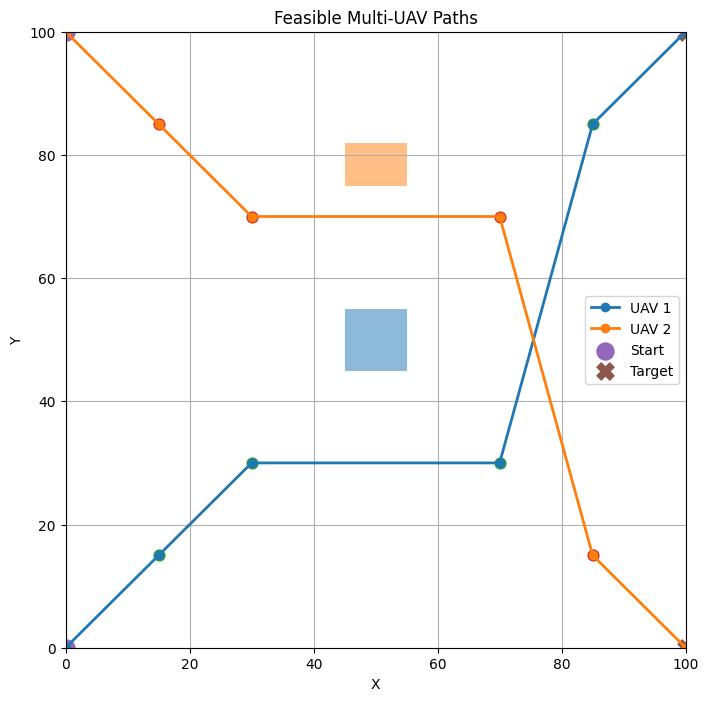

In [22]:
if feasible:

    plot_solution(
        waypoints_feasible,
        "Feasible Multi-UAV Paths"
    )

else:

    print("The solution is infeasible and will not be plotted.")

In [23]:
# Fitness weights

w1 = 0.5
w2 = 0.5

In [24]:
def calculate_fitness(f1, f2):

    fitness = w1 * f1 + w2 * f2

    return fitness

In [25]:
# Calculate fitness for the feasible solution

fitness_feasible = calculate_fitness(
    f1,
    f2
)

print("Objective 1 - Total number of waypoints:", f1)
print("Objective 2 - Total path length:", f2)
print("Fitness:", fitness_feasible)

Objective 1 - Total number of waypoints: 8
Objective 2 - Total path length: 321.2967631234924
Fitness: 164.6483815617462


In [26]:
# Fixed infeasible waypoint locations

waypoints_infeasible = [

    # UAV 1
    np.array([
        [15, 15],
        [30, 30],
        [70, 20],
        [85, 85]
    ]),

    # UAV 2
    np.array([
        [15, 85],
        [35, 30],
        [75, 40],
        [85, 15]
    ])
]

In [27]:
# Create paths for the infeasible solution

paths_infeasible = create_paths(
    waypoints_infeasible
)

print("UAV 1 path:")
print(paths_infeasible[0])

print("\nUAV 2 path:")
print(paths_infeasible[1])

UAV 1 path:
[[  0   0]
 [ 15  15]
 [ 30  30]
 [ 70  20]
 [ 85  85]
 [100 100]]

UAV 2 path:
[[  0 100]
 [ 15  85]
 [ 35  30]
 [ 75  40]
 [ 85  15]
 [100   0]]


In [28]:
# Check feasibility of the infeasible solution

feasible, message_bad = check_feasibility(
    waypoints_infeasible
)

print("Feasible:", feasible)
print("Result:", message_bad)

Feasible: False
Result: UAV separation violation. Minimum distance = 5.00, required = 10


In [29]:
def plot_solution(waypoints, title):

    paths = create_paths(waypoints)

    plt.figure(figsize=(8, 8))

    # Plot obstacles
    for obstacle in obstacles:

        x_min, x_max, y_min, y_max = obstacle

        plt.fill(
            [x_min, x_max, x_max, x_min],
            [y_min, y_min, y_max, y_max],
            alpha=0.5
        )

    # Plot UAV paths
    for i, path in enumerate(paths):

        plt.plot(
            path[:, 0],
            path[:, 1],
            marker='o',
            linewidth=2,
            label=f'UAV {i+1}'
        )

        # Plot waypoints
        plt.scatter(
            waypoints[i][:, 0],
            waypoints[i][:, 1],
            s=60
        )

    # Plot starts
    plt.scatter(
        starts[:, 0],
        starts[:, 1],
        marker='o',
        s=150,
        label='Start'
    )

    # Plot targets
    plt.scatter(
        targets[:, 0],
        targets[:, 1],
        marker='X',
        s=150,
        label='Target'
    )

    plt.xlim(0, X_MAX)
    plt.ylim(0, Y_MAX)

    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title)

    plt.grid()
    plt.legend()
    plt.show()

In [30]:
if feasible:

    plot_solution(
        waypoints_feasible,
        "Feasible Multi-UAV Paths"
    )

else:

    print("The solution is infeasible and will not be plotted.")

The solution is infeasible and will not be plotted.
